# Introduction to Machine Learning - Dr. Sajjd Amini

### Practical Homework 1
#### Sharif Uni. of Tech. - EE Dep. - 1404-2 Semester
#### Deadline: Ordibehesht 19th 1404 | May 9th 2026


**Note**: 
- You are allowed, and also suggested, to use Numpy, Pandas, Scikit, and Matplotlib libraries, UNLESS IT IS EXPLICITLY ADVISED OTHERWISE. <br>
- Load all the dependecies of a cell inside itself, do not create inter-cell dependence for files, libraries and variables

**

## Part 0: Information

Personal identification details have been omitted from this public portfolio copy.

<hr>
<hr>

## Part 1: Minor Problems
#### 40 Points in total
Solve each of the following problems in its own cell, and preferrably, do not use data/functions from other cells

#### **Problem 1.1**: Beta Distribution Update - Bernoulli Likelihood (5 Points) <br>

**Scenario:** <br>
$\theta$ is the parameter of a Bernoulli distribution that produces zeros and ones. <br>
We have a prior beta distribution with parameters `a=3` and `b=4` => P($\theta$) <br>
We have observed the data that is stored in `./datasets/p1_1.json` => P(D|$\theta$) <br>
We want to update our belief about theta with respect to the observed data => P($\theta$|D) **(the order of sample should be preserved!)**

**Your Task:** 
- Simulate the entire scenario, and plot the prior and posterior distributions. 
- Create two functions, like $f_{prior}(x)$ and $f_{posterior}(x)$, that would return the CDF of prior and posterior distributions when called, and also verify them


Posterior parameters: alpha = 40, beta = 17


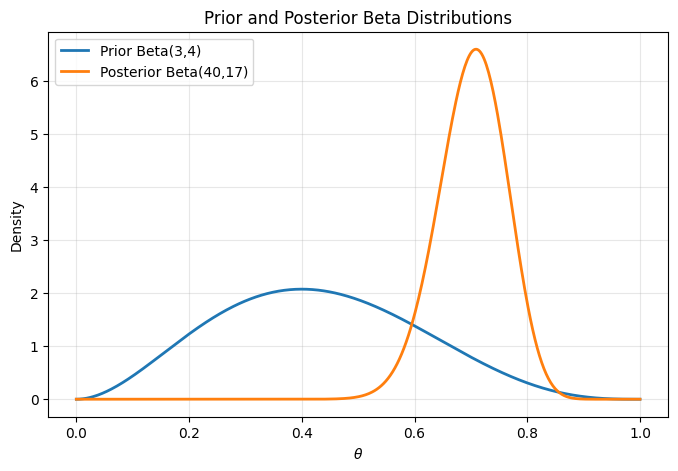

x: [0.   0.25 0.5  0.75 1.  ]
Prior CDF: [0.         0.16943359 0.65625    0.96240234 1.        ]
Posterior CDF: [0.00000000e+00 3.96196443e-13 9.20777394e-04 7.82859231e-01
 1.00000000e+00]


In [4]:
#problem 1.1

import json
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

with open('./datasets/p1_1.json', 'r') as f:
    data = json.load(f)

data = np.array(data["data"])
n = len(data)
s = np.sum(data) 

a_prior = 3
b_prior = 4

a_post = a_prior + s
b_post = b_prior + n - s

print(f"Posterior parameters: alpha = {a_post}, beta = {b_post}")

x = np.linspace(0, 1, 500)

prior_pdf = beta.pdf(x, a_prior, b_prior)
posterior_pdf = beta.pdf(x, a_post, b_post)

plt.figure(figsize=(8,5))
plt.plot(x, prior_pdf, label=f'Prior Beta({a_prior},{b_prior})', lw=2)
plt.plot(x, posterior_pdf, label=f'Posterior Beta({a_post},{b_post})', lw=2)
plt.title('Prior and Posterior Beta Distributions')
plt.xlabel(r'$\theta$')
plt.ylabel('Density')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

def f_prior(x_val):
    return beta.cdf(x_val, a_prior, b_prior)

def f_posterior(x_val):
    return beta.cdf(x_val, a_post, b_post)

x_val = np.linspace(0, 1, 5)
print("x:", x_val)
print("Prior CDF:", f_prior(x_val))
print("Posterior CDF:", f_posterior(x_val))


<hr>

#### **Problem 1.2**: Beta Distribution Update - Binomial Likelihood (5 Points) <br>

**Scenario**: <br>
Repeat the Problem 1.1; but this time, we assume that our observation is not the exact sequence, but just the number of ones and zeros that have occured as a result of the Bernoulli Distritubion. The observed data is stored in `./datasets/p1_1.json`


In [2]:
# Problem 1.2


<hr>

#### **Problem 1.3**: Discrete Random Variable - ML vs MAP update (5 Points) <br>

**Scenario:**
Imagine a dice, with unknown probability for each face to show up. <br> 
- We assume the following prior:
    - $P(X=1)=\frac{1}{2}$
    - $P(X=2)=\frac{1}{4}$
    - $P(X=3)=\frac{1}{8}$
    - $P(X=4)=\frac{1}{16}$
    - $P(X=5) = \frac{1}{32}$
    - $P(X=6) = \frac{1}{32}$ <br>

We throw it a thousand times and and our observed data is stored in the `./dataset/p1_3.json`. <br>

**Your Task:** <br>
- Perform ML and MAP update on the distribution $P(X)$. 
- Draw the prior, likelihood and posterior distribution (or histograms)

**NOTE: IMPLEMENT THE ENTIRE BAYESIAN UPDATING PROCEDURE. DO NOT USE BUILT-IN FUNCTIONS EVEN IF AVAILABLE**

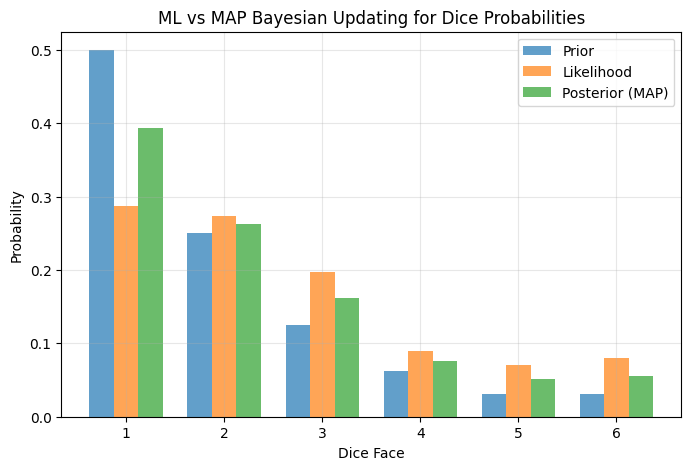


Counts: [287 274 198  90  71  80]
ML estimate: [0.287 0.274 0.198 0.09  0.071 0.08 ]
MAP estimate: [0.3942 0.2623 0.1615 0.076  0.0508 0.0553]
Prior: [0.5    0.25   0.125  0.0625 0.0312 0.0312]


In [9]:
# Problem 1.3

import json
import numpy as np
import matplotlib.pyplot as plt

with open('./datasets/p1_3.json', 'r') as f:
    data = json.load(f)

data = np.array(data["observations"])
faces = np.arange(1, 7)

#Prior 
prior_probs = np.array([1/2, 1/4, 1/8, 1/16, 1/32, 1/32])
prior_counts = prior_probs * 1000

n_counts = np.array([(data == i).sum() for i in faces])
N = np.sum(n_counts)

# ML estimate 
p_ML = n_counts / N

# MAP estimate 
p_MAP = (prior_counts + n_counts - 1)
p_MAP = p_MAP / np.sum(p_MAP)


likelihood = n_counts / np.sum(n_counts)

bar_width = 0.25
x_start = np.arange(6)
plt.figure(figsize=(8,5))
plt.bar(x_start - bar_width, prior_probs, width=bar_width, label='Prior', alpha=0.7)
plt.bar(x_start, likelihood, width=bar_width, label='Likelihood', alpha=0.7)
plt.bar(x_start + bar_width, p_MAP, width=bar_width, label='Posterior (MAP)', alpha=0.7)
plt.xticks(x_start, faces)
plt.xlabel("Dice Face")
plt.ylabel("Probability")
plt.title("ML vs MAP Bayesian Updating for Dice Probabilities")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("\nCounts:", n_counts)
print("ML estimate:", p_ML.round(4))
print("MAP estimate:", p_MAP.round(4))
print("Prior:", prior_probs.round(4))


<hr>

#### **Problem 1.4**: MVN and Hinton Diagram (10 Points) <br>

*To find out about the Hinton Diagram, check out Figure 3.7 in Probabilistic Machine Learning (Kevin Murphy) Vol. 1*

**Scenario:** <br>
We want to see how updating a Multi-variate Normal distribution improves the error of imputing missing values. We're going to assume Standard Multi-Variate Normal prior and update that after observing some data, and use the updated model to impute missing values from a set of vectors.

There are 400 observations recorded in `./datasets/p1_4_train.npz` which will be used to update the model <br>
There are 10 test vectors, with missing values indicated by np.NA in `./dataset/p1_4_test_missing.npz` <br>
The same vectors, without any missing value are available in `./dataset/p1_4_test_full.npz` <br>

We want to witness the gradual improvement of the error <br>
The error is defined as the: $$\text{MSE} = \frac{1}{n}\sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$ where y_i is one of the 10 test vectors. <br>
Be careful not to use test vectors to fit the model <br>

**Your Task:**
- Update the model sequentially, once with 20 samples, once with 40, and so on until 400 data samples, and with each model, calculate the MSE and plot the MSE vs number of data samples.
- Explain the final error plot. (The trend, the error floor, etc.)
- Plot Hinton Diagram of 3 of the test vectors for the final step of the model training (trained on the entire dataset)


N= 20 | MSE: 0.48682
N= 40 | MSE: 0.45284
N= 60 | MSE: 0.45357
N= 80 | MSE: 0.45146
N=100 | MSE: 0.46042
N=120 | MSE: 0.47272
N=140 | MSE: 0.48189
N=160 | MSE: 0.48427
N=180 | MSE: 0.49247
N=200 | MSE: 0.48737
N=220 | MSE: 0.47452
N=240 | MSE: 0.47453
N=260 | MSE: 0.47407
N=280 | MSE: 0.47227
N=300 | MSE: 0.47765
N=320 | MSE: 0.47546
N=340 | MSE: 0.47062
N=360 | MSE: 0.47058
N=380 | MSE: 0.47516
N=400 | MSE: 0.47364


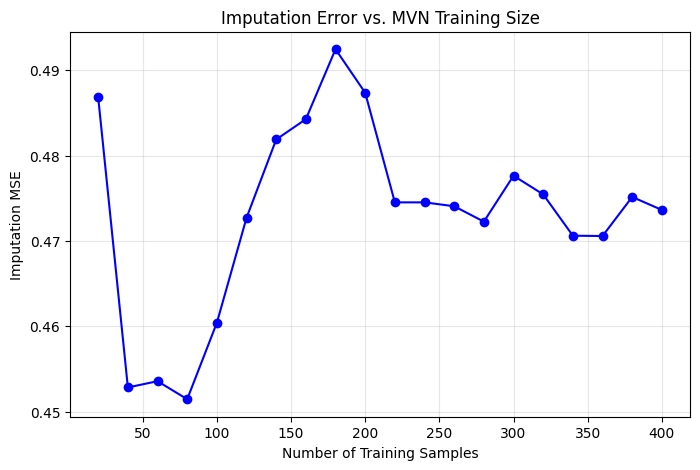

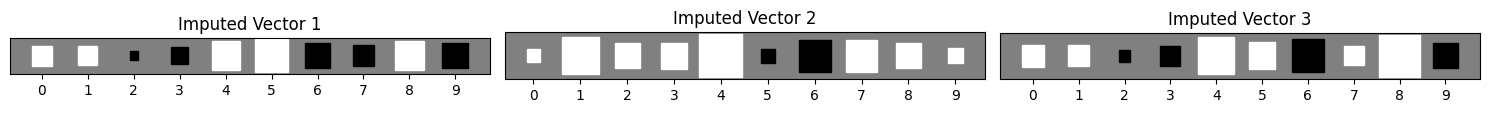

In [71]:
# Problem 1.4

import numpy as np
import matplotlib.pyplot as plt
import os

base_path = "./datasets"
train_path = os.path.join(base_path, "p1_4_train.npz")
test_missing_path = os.path.join(base_path, "p1_4_test_missing.npz")
test_full_path = os.path.join(base_path, "p1_4_test_full.npz")


def load_data():

    train_raw = np.load(train_path, allow_pickle=True)['data']
    test_miss_raw = np.load(test_missing_path, allow_pickle=True)['data']
    test_full_raw = np.load(test_full_path, allow_pickle=True)['data']

    X_train = train_raw.astype(float)
    X_test_full = test_full_raw.astype(float)
    
    X_test_missing = np.full(test_miss_raw.shape, np.nan)
    for i in range(test_miss_raw.shape[0]):
        for j in range(test_miss_raw.shape[1]):

            val = test_miss_raw[i, j]

            if val is not None and not isinstance(val, str):
                X_test_missing[i, j] = float(val)

    return X_train, X_test_missing, X_test_full

X_train, X_test_missing, X_test_full = load_data()

def impute_mvn(x_vec, mu, Sigma):

    x = x_vec.copy()
    miss_idx = np.isnan(x)
    obs_idx = ~miss_idx

    mu_o = mu[obs_idx]
    mu_m = mu[miss_idx]
    Sigma_oo = Sigma[np.ix_(obs_idx, obs_idx)]
    Sigma_mo = Sigma[np.ix_(miss_idx, obs_idx)]

    x_miss_imputed = mu_m + Sigma_mo @ np.linalg.solve(Sigma_oo, (x[obs_idx] - mu_o))
    
    x[miss_idx] = x_miss_imputed
    return x

sample_sizes = np.arange(20, 420, 20)
mse_list = []

for n in sample_sizes:
    X_sub = X_train[:n]
    
    mu = np.mean(X_sub, axis=0)
    Sigma = np.cov(X_sub, rowvar=False) + np.eye(X_sub.shape[1]) * 1e-6

    X_imputed = np.array([impute_mvn(row, mu, Sigma) for row in X_test_missing])
    
    # MSE
    err = np.mean((X_test_full - X_imputed)**2)
    mse_list.append(err)
    print(f"N={n:3d} | MSE: {err:.5f}")

plt.figure(figsize=(8, 5))
plt.plot(sample_sizes, mse_list, marker='o', linestyle='-', color='blue')
plt.xlabel("Number of Training Samples")
plt.ylabel("Imputation MSE")
plt.title("Imputation Error vs. MVN Training Size")
plt.grid(True, alpha=0.3)
plt.show()


def hinton(matrix, ax=None):

    ax = ax or plt.gca()
    ax.set_facecolor('gray')
    ax.set_aspect('equal', 'box')
    
    max_weight = 2 ** np.ceil(np.log2(np.max(np.abs(matrix)) + 1e-12))

    for (y, x), w in np.ndenumerate(matrix):
        color = 'white' if w > 0 else 'black'
        size = np.sqrt(np.abs(w) / max_weight)
        rect = plt.Rectangle([x - size / 2, y - size / 2], size, size,facecolor=color, edgecolor=color)
        ax.add_patch(rect)

    ax.autoscale_view()
    ax.invert_yaxis()

mu_final = np.mean(X_train, axis=0)
Sigma_final = np.cov(X_train, rowvar=False)
X_final_imputed = np.array([impute_mvn(row, mu_final, Sigma_final) for row in X_test_missing])

fig, axes = plt.subplots(1, 3, figsize=(15, 3))
for i, ax in enumerate(axes):
    hinton(X_final_imputed[i].reshape(1, -1), ax=ax)
    ax.set_title(f"Imputed Vector {i+1}")
    ax.set_xticks(range(X_final_imputed.shape[1]))
    ax.set_yticks([])

plt.tight_layout()
plt.show()




As we add more training data, the imputation error drops quickly at first, showing that the model is learning useful patterns.

Sometimes the error goes up or down a bit in the middle because the model is still adjusting as it gets more data.

Eventually, the error stops improving and settles at a final level, this is called the “error floor.”

The error floor happens because of random noise in the data and the limits of the MVN model.

Overall, more data helps at the start, but after a point, the model can’t get much better.

<hr>

#### **Problem 1.5**: Decision Tree (10 Points) <br><br>

In this problem, you are given a dataset of 1500 samples of recorded Weight, Speed, and Burrow Depth of 3 differenet species of animals in the file `./datasets/p1_5_animal_species.csv`
- A: Fox
- B: Hare
- C: Mole <br> <br>

There is also a test dataset, which you'll be using to test the decision that you have arrived at: `./datasets/p1_5_test.csv`

**Your Task:** <br>
Create a decision tree based on some sepearation test between random variables: KL-Divergence, Correlation Test, or anything else, it's your choice.
<br>
Make sure you plot the Decision Tree Surface, here is an example of it, for the classification of certain type of flower:
<br>
Explain why you chose (or your algorithm setteled at) the splitting critrion of each node of the tree
<br>
<div align="center">
    <img src="./pictures/decision_tree_surface.png" width="400">
    <p>Figure 1: Example of Decision Tree Surface</p>
</div>

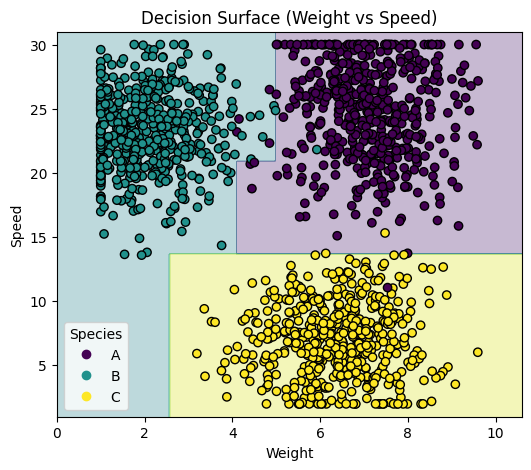

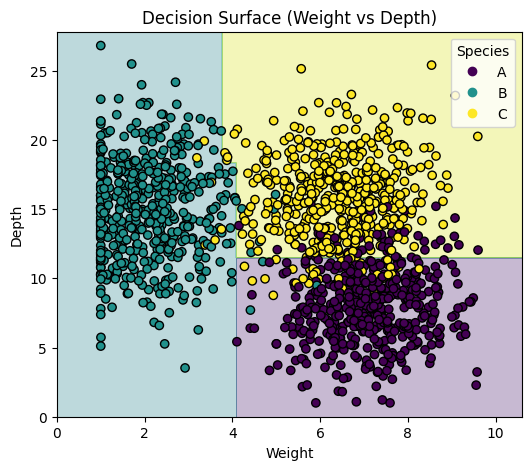

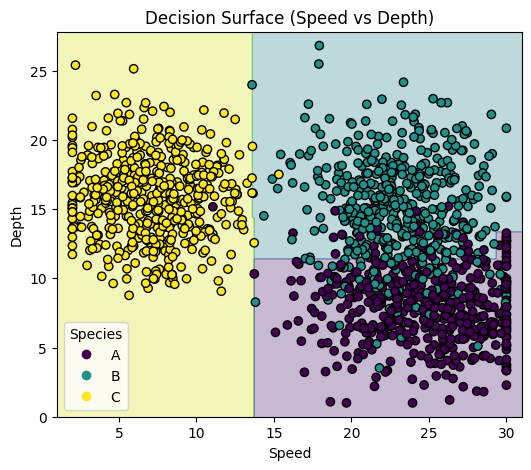

In [86]:
# Problem 1.5

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder


train_data = pd.read_csv("./datasets/p1_5_animal_species.csv")

X = train_data[["Weight", "Speed", "Depth"]].values
y = train_data["Species"].values

le = LabelEncoder()
y_encoded = le.fit_transform(y)


tree = DecisionTreeClassifier(
    criterion="entropy",  # information gain
    max_depth=4,
    random_state=42
)

tree.fit(X, y_encoded)


test_data = pd.read_csv("./datasets/p1_5_test.csv")
X_test = test_data[["Weight", "Speed", "Depth"]].values

predictions = tree.predict(X_test)
predictions = le.inverse_transform(predictions)


def plot_decision_surface(feature_x, feature_y):

    X_plot = train_data[[feature_x, feature_y]].values
    y_plot = y_encoded

    model = DecisionTreeClassifier(criterion="entropy", max_depth=4)
    model.fit(X_plot, y_plot)

    x_min, x_max = X_plot[:,0].min()-1, X_plot[:,0].max()+1
    y_min, y_max = X_plot[:,1].min()-1, X_plot[:,1].max()+1

    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),np.linspace(y_min, y_max, 300))

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(6,5))
    plt.contourf(xx, yy, Z, alpha=0.3)

    scatter = plt.scatter(X_plot[:,0], X_plot[:,1], c=y_plot, edgecolor='k')

    plt.xlabel(feature_x)
    plt.ylabel(feature_y)
    plt.title(f"Decision Surface ({feature_x} vs {feature_y})")

    handles, _ = scatter.legend_elements()
    plt.legend(handles, le.classes_, title="Species")

    plt.show()

plot_decision_surface("Weight", "Speed")
plot_decision_surface("Weight", "Depth")
plot_decision_surface("Speed", "Depth")


The decision tree uses information gain based on entropy to determine the splitting rule at each node. Entropy measures the impurity of a node, meaning how mixed the class labels are within that node. The algorithm evaluates different feature thresholds and selects the split that produces the largest reduction in entropy, resulting in more homogeneous child nodes.

At each node, the tree examines the three features (Weight, Speed, and Burrow Depth) and chooses the feature and threshold that best separates the animal species. For example, one node may split based on Weight if that variable best distinguishes foxes from the other animals. Another node may split based on Burrow Depth, which is useful for separating moles (which dig deep burrows) from foxes and hares.

This recursive splitting process continues until the nodes become sufficiently pure or the maximum depth is reached. The resulting tree forms decision boundaries that separate the species based on their physical characteristics. The decision surface plots visualize these boundaries in the feature space.

<hr>

#### **Problem 1.6**: Linear Gaussian Systems (Sensor Fusion) (10 Points) <br> <br>

In this problem, we are going to fuse the signals that were recorded with different sensors, each having its own precison. We wish to find the best estimation of the value that is being measured by different sensors. The data of all sensors are provided in the `./dataset/p1_6_sensor_data.npz`. 200 data samples, samples 1-50 belong to sensor set 1, 51-100 to sensor set 2, and so on. We do not know the Mean or Covariance of any of the sensor sets a priori. The path to the final distribution is rather straight-forward, so your task here is, mainly, to adderss the upcoming questions (And verify them with the simulation)

**Your Tasks:** <br>
- Explain why the final distribution is as it is. Why is it gravitated towards any particular direction?  
- Which sensor is the least informative? What difference does it make if we DO NOT include it in our measurement? 
- What diffrence would it make if we perform the distribution updating (sensor fusion) in any other order? (For example, would that make any difference to first update the prior with the data of sensor 1 and then sensor 2, or vice versa)

Individual Sensor Estimates: 

Sensor 1
Estimated mean: [4.9772 1.765 ]
Covariance trace: 2.1857

Sensor 2
Estimated mean: [3.8491 3.0443]
Covariance trace: 2.0634

Sensor 3
Estimated mean: [5.3887 3.612 ]
Covariance trace: 2.4075

Sensor 4
Estimated mean: [6.2852 2.1926]
Covariance trace: 7.8917

 Final Fused Estimate (All Sensors): 
Fused Mean:
 [5.0501524  3.08091843]
Fused Covariance Trace:
 0.16381857914654485

 Least Informative Sensor: 
Sensor 4 is the least informative (Highest trace: 7.8917)

 Fused Estimate (without least informative sensor): 
Mean without sensor:
 [5.02667326 3.10115929]
Difference in Mean:
 [0.02347914 0.02024086]
Difference in Covariance Trace:
 0.003511315461178277

 Testing different fusion orders: 
Order [1, 2, 3, 4] - Mean: [5.0502 3.0809]  and Trace: 0.163819
Order [4, 3, 2, 1] - Mean: [5.0502 3.0809]  and Trace: 0.163819
Order [2, 4, 1, 3] - Mean: [5.0502 3.0809]  and Trace: 0.163819


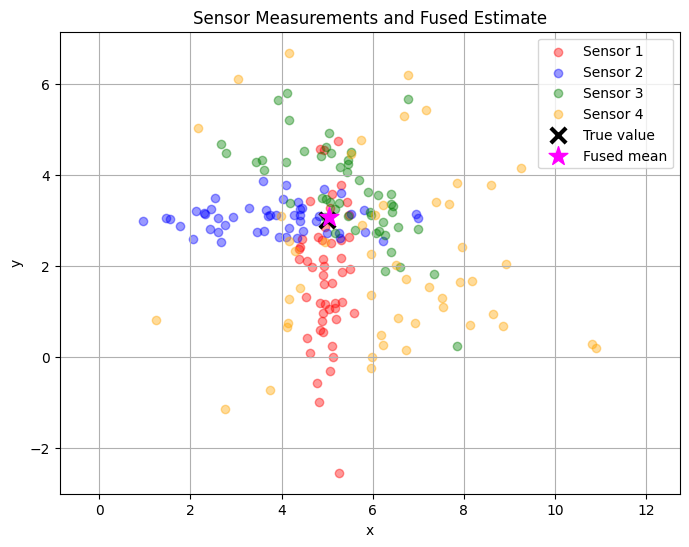

In [77]:
# Problem 1.6
import numpy as np
import matplotlib.pyplot as plt

file_path = "./datasets/p1_6_sensor_data.npz"
data = np.load(file_path)

sensor_sets = [
    data["sensor_1"],
    data["sensor_2"],
    data["sensor_3"],
    data["sensor_4"]
]

true_value = data["true_value"]

means = []
covs = []

print("Individual Sensor Estimates: ")
for i, s in enumerate(sensor_sets):
    mu = np.mean(s, axis=0)
    cov = np.cov(s, rowvar=False)

    cov = cov + 1e-6 * np.eye(cov.shape[0])

    means.append(mu)
    covs.append(cov)

    print(f"\nSensor {i+1}")
    print("Estimated mean:", np.round(mu, 4))
    print("Covariance trace:", round(np.trace(cov), 4))


def fuse(mu1, S1, mu2, S2):
    P1 = np.linalg.inv(S1)
    P2 = np.linalg.inv(S2)

    Sf = np.linalg.inv(P1 + P2)
    muf = Sf @ (P1 @ mu1 + P2 @ mu2)

    return muf, Sf

mu_fused = means[0]
cov_fused = covs[0]

for i in range(1, 4):
    mu_fused, cov_fused = fuse(mu_fused, cov_fused, means[i], covs[i])

print("\n Final Fused Estimate (All Sensors): ")
print("Fused Mean:\n", mu_fused)
print("Fused Covariance Trace:\n", np.trace(cov_fused))


#least informative sensor
traces = [np.trace(cov) for cov in covs]
least_sensor = np.argmax(traces)

print("\n Least Informative Sensor: ")
print(f"Sensor {least_sensor + 1} is the least informative (Highest trace: {traces[least_sensor]:.4f})")

remaining_indices = [i for i in range(4) if i != least_sensor]

mu_wo = means[remaining_indices[0]]
cov_wo = covs[remaining_indices[0]]

for i in remaining_indices[1:]:
    mu_wo, cov_wo = fuse(mu_wo, cov_wo, means[i], covs[i])

print("\n Fused Estimate (without least informative sensor): ")
print("Mean without sensor:\n", mu_wo)
print("Difference in Mean:\n", np.abs(mu_fused - mu_wo))
print("Difference in Covariance Trace:\n", np.abs(np.trace(cov_fused) - np.trace(cov_wo)))


# different fusion orders
print("\n Testing different fusion orders: ")
orders = [
    [0, 1, 2, 3],
    [3, 2, 1, 0],
    [1, 3, 0, 2]
]

for order in orders:
    mu = means[order[0]]
    cov = covs[order[0]]

    for i in order[1:]:
        mu, cov = fuse(mu, cov, means[i], covs[i])

    print(f"Order {[x+1 for x in order]} - Mean: {np.round(mu, 4)}  and Trace: {np.trace(cov):.6f}")

# Plotting
if sensor_sets[0].shape[1] == 2:
    colors = ["red", "blue", "green", "orange"]

    plt.figure(figsize=(8, 6))

    for i, s in enumerate(sensor_sets):
        plt.scatter(s[:, 0], s[:, 1], alpha=0.4, color=colors[i], label=f"Sensor {i+1}")

    plt.scatter(true_value[0], true_value[1], color="black", marker="x", s=120, linewidths=3, label="True value")
    plt.scatter(mu_fused[0], mu_fused[1], color="magenta", marker="*", s=200, label="Fused mean")

    plt.title("Sensor Measurements and Fused Estimate")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend()
    plt.grid(True)
    plt.axis("equal")
    plt.show()


**1. Why does the final distribution look the way it does?**

The final distribution is obtained by fusing the Gaussian estimates from all sensors. Each sensor provides:

a mean vector, which represents the center of its measurements,
a covariance matrix, which represents its uncertainty.
In Gaussian fusion, each sensor is weighted by its precision, which is the inverse of its covariance matrix. Therefore, a sensor with lower uncertainty has a larger influence on the final estimate, while a sensor with higher uncertainty contributes less.

The fused covariance is given by:

$$
\Sigma_f = \left(\Sigma_1^{-1} + \Sigma_2^{-1} + \Sigma_3^{-1} + \Sigma_4^{-1}\right)^{-1}
$$

and the fused mean is:

$$
\mu_f =
\Sigma_f \left(
\Sigma_1^{-1}\mu_1 +
\Sigma_2^{-1}\mu_2 +
\Sigma_3^{-1}\mu_3 +
\Sigma_4^{-1}\mu_4
\right)
$$

This explains why the final distribution is pulled toward a particular direction: it is naturally attracted toward the sensors with higher precision (smaller covariance). In the simulation, this can be observed by noting that the fused mean lies closer to the measurement clusters that have smaller spread.

Also, the fused covariance is smaller than the individual sensor covariances, which means that the final estimate is more certain than the estimate of any single sensor alone.

**2. Which sensor is the least informative?**

A simple way to measure the informativeness of a sensor is by using the trace of its covariance matrix:

trace(Σ)

The trace represents the total variance of the sensor estimate. Therefore:

a large trace means high uncertainty and low informativeness,
a small trace means low uncertainty and high informativeness.
So, the least informative sensor is the one with the largest covariance trace.

In this case the least informative sensor is tested to be sensor 4 which has the highest total variance compared to other sensors.

 *- What happens if we exclude it?*

If the least informative sensor is removed and the remaining sensors are fused again, the following is usually observed:

the fused mean changes only slightly,
the fused covariance may become slightly smaller.
This happens because the least informative sensor has a large uncertainty, so its contribution to the final result is weak. In many cases, removing it does not significantly affect the fused estimate, because the more precise sensors already dominate the fusion result.

Thus, excluding the least informative sensor often produces nearly the same estimate, sometimes with a slightly cleaner or more confident final covariance.

**3. Does the order of fusion matter?**

In theory, no. The order of fusion should not change the final result.

This is because Gaussian fusion is based on the addition of precision matrices and matrix addition is both commutative and associative. That means:

$$
(\Sigma_1^{-1} + \Sigma_2^{-1}) + \Sigma_3^{-1}
=
\Sigma_1^{-1} + (\Sigma_2^{-1} + \Sigma_3^{-1})
$$


As a result, sequential fusion gives the same final distribution regardless of the order:

((1⊕2)⊕3)⊕4=1⊕(2⊕(3⊕4))

So fusing sensors in the order

Sensor 1 → Sensor 2 → Sensor 3 → Sensor 4
or in the reverse order

Sensor 4 → Sensor 3 → Sensor 2 → Sensor 1
should theoretically produce the same fused mean and covariance.

*- What does the simulation show?*

The simulation confirms this result. When different fusion orders are tested, the final fused mean and covariance are almost identical. Any tiny differences that appear are only due to numerical floating-point rounding errors, not because the fusion process actually depends on order.

Therefore, both theory and simulation show that Gaussian sensor fusion is order-independent.

<hr>
<hr>

## Part 2: Bayesian Network (25 Points)

Bayesian Network is a graphical representation of conditional independence of random variables. Each random variable is shown with a node, and their dependence is modeled with directed edges. If a directed edge point to B from A, it means that A is a parent of B. So how is the graph supposed to encode the depencde among the RVs? We have a simple rule for that: **Each random variable is indepent of Non-descendant RVs, conditioned on its parents**, or in mathematical terms:
$$X_i \perp \text{NonDescendants}(X_i) \mid \text{Pa}(X_i)$$
$Pa(X_i)$ referes to the set of parents of $X_i$ <br>
Non-descendants = *all nodes except $X_i$, its parents, and its descendants*



Look at the image below

<div align="center">
    <img src="./pictures/bn.png" width="400">
    <p>Figure 2: A simple bayesian network</p>
</div>

In this example, $X_1$ and $X_2$ are parents of $X_3$, and $X_3$ is the only parent of $X_4$. So we know that $X_4 \perp X_1, X_2 \mid X_3$

Let's assume that order of random variables index is preserved - which means that parents of a certain node have lower index than the node itself. In this case, the conditional indepence property that we stated earlier can be re-written in the following way (Local Markov Property):
$$P(X_i \mid X_1, \ldots, X_{i-1}) = P(X_i \mid \text{Pa}(X_i))$$
<br>


We have a dataset of consisting of 5 indicators in stock market: 
- $X_1$: Market Sentiment, 
- $X_2$: Trading Volume,
- $X_3$: Stock Price, 
- $X_4$: Volatility, 
- $X_5$: Option Volume <br>

The data can be found in `./datasets/causal_stock_data.csv`. 

**Your Tasks:** <br>
You will be IMPLEMENTING an algorithm to use conditional independence test to figure out the Bayesian Network. You can use come up with your own idea, or use well-known methods like Peter-Clark or SGS. There is no need for data denoising, due to current network connection issue, the data is completely synthetic. Also, the related libraries like NetworkX are probably unreachable, so implementation in Numpy and demonstration in any library that you already have (regardless of how dirty it might look for bayesian networks) is accepted. Don't take it hard on yourselves. <br> <br>

**NOTE:** <br> You are **NOT ALLOWED** to use built-in libraries and functions that solve the problem in just one line. Your task is to **EXPLICITLY** implement the algorithm even if you use Peter-Clark or SGS or anything else. No point will be lost if you come up with your own algorithm and it does not turn out to be perfect


X1 has no parents
Parents of X2: ['X1']
Parents of X3: ['X2']
Parents of X4: ['X1', 'X2']
Parents of X5: ['X3']


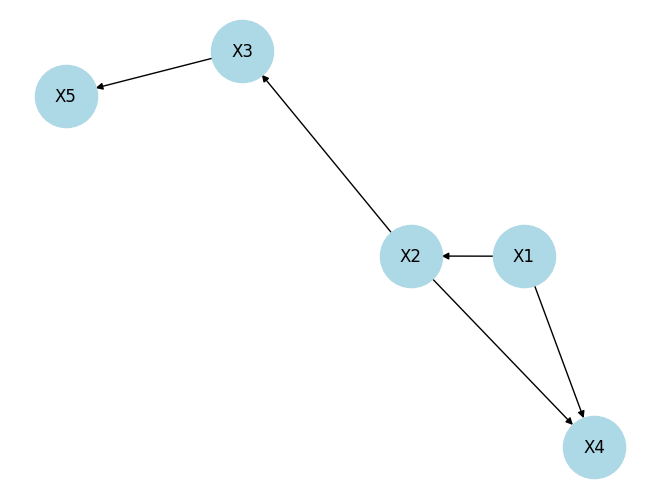

In [32]:
# Problem 2

import numpy as np
import pandas as pd
from itertools import combinations
from scipy.stats import pearsonr
import networkx as nx
import matplotlib.pyplot as plt


data = pd.read_csv("./datasets/causal_stock_data.csv")
X = data.values
n_samples, n_vars = X.shape


def regression_residuals(b, A):
    
    if A.size == 0:
        return x
    
    A = np.column_stack([np.ones(len(A)), A])
    
    pseudo_x = np.linalg.inv(A.T @ A) @ A.T @ b
    prediction = A @ pseudo_x
    
    residuals = b - prediction
    return residuals


def corr_test(x, y, Z):
    
    rx = regression_residuals(x, Z)
    ry = regression_residuals(y, Z)
    
    corr, p_value = pearsonr(rx, ry)
    
    return corr, p_value

alpha = 0.05
parents = {i: [] for i in range(n_vars)}

for i in range(n_vars):

    candidates = list(range(i))
    
    for j in candidates:
    
        cond_set = [k for k in candidates if k != j]
        
        if len(cond_set) == 0:
            Z = np.empty((n_samples, 0))
        else:
            Z = X[:, cond_set]
        
        corr, p_val = corr_test(X[:, i], X[:, j],Z)
        
        if p_val < alpha:
            parents[i].append(j)


for child, pa in parents.items():
    
    if len(pa) == 0:
        print(f"X{child+1} has no parents")
    else:
        parent_names = [f"X{p+1}" for p in pa]
        print(f"Parents of X{child+1}: {parent_names}")

G = nx.DiGraph()

for child, pa in parents.items():
    for p in pa:
        G.add_edge(f"X{p+1}", f"X{child+1}")

nx.draw(G, with_labels=True, node_size=2000, node_color="lightblue")
plt.show()


<hr>
<hr>

## Part 3: MiniGPT! (Missing-Token prediction) (35 Points)

In this problem, we're going to create a super-simplifed version of ChatGPT. In simple words, GPTs (Generative Pre-trained Transformers), each word or letter or symbol (depending on the network) is treated a 'Token'. For example this sentence: `The quick brown fox, jumps over the lazy dog` is broken into tokens: {`The`, `quick`, `brown`, `fox`, `,`, `jumps`, `over`, `the`, `lazy`, `dog`}. And each token is represented via a high-dimensional vector. The set of all possible tokens is called the Dictionary. When you ask a chatbot to, for instance, write an essay for you, the chatbot starts with a few words, and the keeps predicting (according to your prompt) the next words (tokens) and priting them out until it has realizes that it has printed enough tokens.
But we are going to take on a simpler approach, we are going to assume each word printed on the screen is a discrete random variable, taking value $t_1$ to $t_n$, where $n$ is the size of dictionary $T$. In mathematical terms:
$$X_j = t_i \ \ \text{with probability} \ \  p_i; \ \ \ \ \ \ \ t_i \in T $$

We have a dataset of 5000 gramatically valid sentences. We want to create a function, let's say $f(X)$, to predict the missing word. The input to this function consists of $X: \text{A sentence with a missing value}$ and we denote $X=\{ X_1, ..., X_k \}$, where each $X_i$ represents a random variable that can take any value $t_i \in T$. EXACTLY ONE WORD inside the input sentence is supposed to be missing, and the length of the sentence is not fixed. We wish to have a function $f(X)$ that predicts the true value of this sentence. Normally, such functions calculate a score for each candidate (all elements of $T$ in this case) on how probable they are given the observed data, and the item with highes score (or probablity, if we use SoftMax) is chosen. 
Our goal is to take advantage of statistical models to capture dependencies in the sequence of the words. You are free choose any statistical (NOT DEEP!) model. Some suggestions are given to provide you with you insight on how to carry on. <br> <br>
**IMPORTANT NOTE:** Make sure that you include `EOS` (End-of-Sequence) as a member of your dictionary $T$. Every sentence **SHOULD** end with `EOS` Token. This is the standrad practice for predicting the end of sequence: Treating it as a token.
<br><br>
Some Ideas:
- Auto-Regressive of order 1: In this model, each RV depends only on the previous RV, so we only need to find the distribution of $P(X_i \mid X_{i-1})$. We can show this in a graph as: $$X_1 \rightarrow X_2 \rightarrow ... \rightarrow X_k$$
- Auto-Regressive of order 2: Just like the previous one, but this time we are dealing with $P(X_i \mid X_{i-1}, X_{i-2})$
- Recurrent: Each RV depends on all the previous ones: $P(X_i \mid X_{1:i-1})$
- Empirical Joint Distribution: Each RV depends on all others: $P(X_i \mid X_{\neq i})$ <br>

**IMPORTANT NOTE:**<br>
Pay attention so the fact that there are TWO SEPARATE MODEL that you should choose an option for: <br>
- 1. Statistical Model: Like the ones mentioned in the previous paragraph, it encodes how the RVs are related to each other
- 2. Statistical Distribution: After the model is set, we need to consider a valid distribution for that, for example $P(X_i \mid X_{i-1})$ can be categorical distribution with multi-variable beta prior. Or it can be just epirical distribtion stored in a table. 


**Your Task:** <br>
You are provided with two dataset: `./datasets/p3_train.json` and `./datasets/p3_test.json`.<br>You should use AT LEAST 3 DIFFERENT STATISTCAL Models to predict the missing word (written as `<MASK>`) in a sentence, and also define a way to address which model has done a better job (like a cost function, or a metric for error).<br>You should also EXPLAIN (literally type it) why one model was superior to the others, and compare all your selected models in terms of flexibility, precision, memory complexity, postrerior calculation complexity, etc.<br>You may also use prior distribution over tokens, that's up to you.
<br><br>
A little help: We mostly care about the grammar, not the exact semantic meaning of the sentence. It is okay if it sounds a little bit bizzare, like "A dog runs on the sky".

In [76]:
import json
import math
from collections import defaultdict, Counter

def load_data(file_path):
    with open(file_path, 'r') as f:
        return json.load(f)

def evaluate_model(model_predict_func, test_data, vocab):
    correct = 0
    total = len(test_data)
    for item in test_data:
        tokens = item['masked_sentence'].split()
        mask_idx = item['mask_position']
        
        predicted_token = model_predict_func(tokens, mask_idx, vocab)
        if predicted_token == item['target_token']:
            correct += 1
            
    return correct / total if total > 0 else 0

def train_models(train_data):
    unigram_counts = Counter()
    bigram_counts = defaultdict(Counter)
    trigram_counts = defaultdict(Counter)
    
    vocab = set(["EOS"])
    
    for item in train_data:
        tokens = item['original_sentence'].split()
        vocab.update(tokens)
        
        for i in range(len(tokens)):
            w_i = tokens[i]
            unigram_counts[w_i] += 1
            
            if i > 0:
                w_prev = tokens[i-1]
                bigram_counts[w_prev][w_i] += 1
                
            if i > 1:
                w_prev2 = tokens[i-2]
                w_prev1 = tokens[i-1]
                trigram_counts[(w_prev2, w_prev1)][w_i] += 1

    vocab_size = len(vocab)
    total_unigrams = sum(unigram_counts.values())
    
    def predict_unigram(tokens, mask_idx, vocab):
        best_token = None
        max_score = -float('inf')
        for t in vocab:
            if t == "<MASK>": continue
            # P(t)
            score = math.log((unigram_counts[t]+ 1 ) / (total_unigrams + vocab_size))
            if score > max_score:
                max_score = score
                best_token = t
        return best_token

    def predict_bigram(tokens, mask_idx, vocab):
        best_token = None
        max_score = -float('inf')
        prev_w = tokens[mask_idx - 1] if mask_idx > 0 else None
        next_w = tokens[mask_idx + 1] if mask_idx < len(tokens) - 1 else None
        
        for t in vocab:
            if t == "<MASK>": continue
            score = 0
            
            # P(t | prev_w)
            if prev_w:
                count_prev = sum(bigram_counts[prev_w].values())
                score += math.log((bigram_counts[prev_w][t] + 1) / (count_prev + vocab_size))
                
            # P(next_w | t)
            if next_w:
                count_t = sum(bigram_counts[t].values())
                score += math.log((bigram_counts[t][next_w] + 1) / (count_t + vocab_size))
                
            if score > max_score:
                max_score = score
                best_token = t
        return best_token

    def predict_trigram(tokens, mask_idx, vocab):
        best_token = None
        max_score = -float('inf')
        
        w_m2 = tokens[mask_idx - 2] if mask_idx > 1 else None
        w_m1 = tokens[mask_idx - 1] if mask_idx > 0 else None
        w_p1 = tokens[mask_idx + 1] if mask_idx < len(tokens) - 1 else None
        w_p2 = tokens[mask_idx + 2] if mask_idx < len(tokens) - 2 else None
        
        for t in vocab:
            if t == "<MASK>": continue
            score = 0
            
            # P(t | w_m2, w_m1)
            if w_m2 and w_m1:
                ctx = (w_m2, w_m1)
                count_ctx = sum(trigram_counts[ctx].values())
                score += math.log((trigram_counts[ctx][t] + 1) / (count_ctx + vocab_size))
                
            # P(w_p1 | w_m1, t)
            if w_m1 and w_p1:
                ctx = (w_m1, t)
                count_ctx = sum(trigram_counts[ctx].values())
                score += math.log((trigram_counts[ctx][w_p1] + 1) / (count_ctx + vocab_size))
                
            # P(w_p2 | t, w_p1)
            if w_p1 and w_p2:
                ctx = (t, w_p1)
                count_ctx = sum(trigram_counts[ctx].values())
                score += math.log((trigram_counts[ctx][w_p2] + 1) / (count_ctx + vocab_size))
                
            if score > max_score:
                max_score = score
                best_token = t
        return best_token

    return vocab, predict_unigram, predict_bigram, predict_trigram

if __name__ == "__main__":

    train_data = load_data('./datasets/p3_train.json')
    test_data = load_data('./datasets/p3_test.json')
        
    vocab, p_uni, p_bi, p_tri = train_models(train_data)
        
    acc_uni = evaluate_model(p_uni, test_data, vocab)
    acc_bi = evaluate_model(p_bi, test_data, vocab)
    acc_tri = evaluate_model(p_tri, test_data, vocab)
        
    print(f"Unigram Accuracy: {acc_uni:.4f}")
    print(f"Bigram Accuracy:  {acc_bi:.4f}")
    print(f"Trigram Accuracy: {acc_tri:.4f}")



Unigram Accuracy: 0.0000
Bigram Accuracy:  0.2640
Trigram Accuracy: 0.2160


The "Bigram model" performed the best (with ~26.40% accuracy) because it hits the “sweet spot” between context and data availability.

The "Unigram model" has no context, so it just guesses the most common word in the language every time (yielding 0% accuracy).

The "Trigram model" looks at too much context. Because human language is highly variable, most specific 3-word sequences in the test set never appeared in the training set. This is called “data sparsity.” Even with smoothing, the Trigram model struggles because it hasn’t seen enough examples of those specific triplets to make confident predictions.

The Bigram model, looking at just 2-word pairs, has seen enough of those pairs in the training data to make smart, accurate guesses.

Comparison of the Models
1. **Precision (Accuracy)**

Unigram: Very poor (0%). It ignores the sentence entirely and only looks at overall word frequency.

Bigram: Best (~26.40%). It uses the immediate left and right neighbors, providing enough context to be accurate without being overly specific.

Trigram: Good, but worse than Bigram (~21.60%). It demands too much specific history, leading to errors when it encounters new 3-word combinations it didn’t see in training.

2. **Flexibility**

Unigram: Highly inflexible. It will predict the exact same word for every single blank, no matter what the rest of the sentence says.

Bigram: Moderately flexible. It adapts its prediction based on the words immediately next to the blank.

Trigram: Extremely sensitive to context. It tries to capture longer phrases and grammar rules. While this makes it theoretically more “flexible” to complex sentence structures, in practice (with limited data), it becomes rigid because it relies too heavily on seeing exact phrases.

3. **Memory Complexity (Storage)**

Let 𝑉 be the size of our vocabulary.
 
Unigram: $O(V)$. It only needs to store the count of each individual word. This takes very little memory (like a 1D list).

Bigram: $𝑂(𝑉^2)$. It needs to store the counts of every word followed by every other word. This takes up a lot more RAM (like a 2D grid).

Trigram: $𝑂(𝑉^3)$. It needs to store counts for 3-word combinations. This requires a massive amount of memory (like a 3D cube). Most of these combinations are zeroes, but it still heavily impacts memory usage.

4. **Posterior Calculation Complexity**

To predict the missing word, all three models must test every single word in the vocabulary to see which one gets the highest score. Therefore, the base complexity is $𝑂(𝑉)$
for all of them. However, the amount of math done per word is different:

Unigram: Fastest. It only does one simple dictionary lookup per vocabulary word.

Bigram: Slower. For every vocabulary word, it has to do two lookups (word before + blank, and blank + word after) and add the logs together.

Trigram: Slowest. For every vocabulary word, it has to do three lookups (involving two words before, and the words after) and more math additions to calculate the final probability.